# TD3 — Inventory MDP, reward, and baseline policies — Support

**Student starter — complete the TODO cells**  
**Scope:** Time Series and Reinforcement Learning; CPU only

## Working and claim contract

Local Python 3.11/3.12 with the locked `uv` environment is the primary path. Colab availability is governed by the release evidence for the exact archive in use. Public base seeds are `11, 23, 37, 51, 71`. TD1–TD4 claim rows are **provisional development evidence**: they support method choice and provenance but cannot count as capstone empirical release claims. Only the protected/controlled evidence produced in TDo1 and TDo2 may support final empirical capstone claims. Restart and run top-to-bottom before handoff.

## Support route

Guidance reduces syntax and navigation load; it does not expose the assessed solution or lower the Core standard.

In [1]:
from pathlib import Path
import os, sys

def locate_course_root(start=Path.cwd()):
    for candidate in [start, *start.parents]:
        if (candidate/'uv.lock').is_file() and (candidate/'shared').is_dir(): return candidate.resolve()
    for lock in start.glob('*/uv.lock'):
        if (lock.parent/'shared').is_dir(): return lock.parent.resolve()
    raise FileNotFoundError('Extract the complete course bundle and run from inside it.')
COURSE_ROOT=locate_course_root(); os.chdir(COURSE_ROOT)
if str(COURSE_ROOT) not in sys.path: sys.path.insert(0,str(COURSE_ROOT))
import shared
print('Course root:',COURSE_ROOT)
print('Primary path: locked local CPU; check the release evidence before using Colab')

Course root: D:\Documents\ESILV\A5\DIA\Machine learning\Advanced_Machine_Learning_ESILV_2026-2027_DVL_final
Primary path: locked local CPU; check the release evidence before using Colab


## Micro-example — reward decomposition

One seeded transition exposes the costs compressed into reward.

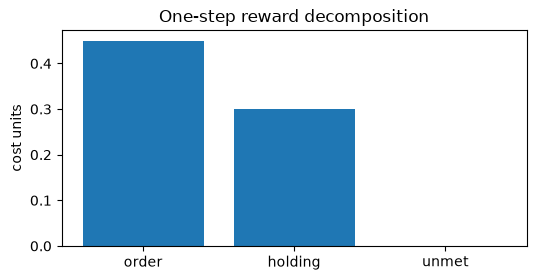

[1 0] [1 0] -0.75 {'order': 0.45, 'holding': 0.3, 'unmet': 0.0}


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from shared.inventory_env import InventoryControlEnv, ORDER_QUANTITIES
env=InventoryControlEnv(); observation,_=env.reset(seed=11)
next_observation,reward,terminated,truncated,info=env.step(1)
terms={'order':env.config.order_cost*info['order_quantity'],'holding':env.config.holding_cost*info['stock_level'],'unmet':env.config.unmet_demand_cost*info['unmet_demand']}
assert np.isclose(sum(terms.values()),info['cost']) and np.isclose(reward,-info['cost']); env.close()
fig,ax=plt.subplots(figsize=(6,2.8)); ax.bar(list(terms),list(terms.values())); ax.set(ylabel='cost units',title='One-step reward decomposition'); plt.show()
print(observation,next_observation,reward,terms)

## 1 — MDP contract and checker

In [3]:
from gymnasium.utils.env_checker import check_env
env=InventoryControlEnv(); check_env(env,skip_render_check=True)
mdp_contract={
    'state':'(stock_level,demand_regime)',  # stock 0..8 after serving demand, regime 0=low / 1=high
    'actions':'indices 0/1/2 -> quantities 0/1/2',  # always map through ORDER_QUANTITIES
    'transition_source':'shared/inventory_env.py InventoryControlEnv.step: immediate replenishment capped at max_stock=8; '
                        'demand ~ regime-conditional categorical (low: {0,1,2} p=.25/.60/.15, high: {1,2,3} p=.15/.55/.30); '
                        'regime follows Markov chain P=[[.85,.15],[.20,.80]]; randomness from env.np_random seeded at reset',
    'reward':'reward = -cost, cost = 0.45*order_qty + 0.30*end_stock + 3.0*unmet_demand (cost units per step)',
    'horizon':env.config.horizon,
    'horizon_semantics':'continuing task cut by a time limit: terminated is always False, truncated=True at step 40 '
                        '(bootstrap through truncation, never treat step 40 as an absorbing terminal state)',
}
assert tuple(env.observation_space.nvec)==(9,2) and env.action_space.n==3 and env.config.horizon==40
assert env.observation_space.shape==(2,)
# Executable horizon check: run one episode and confirm truncation (not termination) happens exactly at step 40
obs,_=env.reset(seed=11); t=0; terminated=truncated=False
while not (terminated or truncated):
    obs,r,terminated,truncated,info=env.step(0); t+=1
assert t==40 and truncated and not terminated
env.close(); mdp_contract

{'state': '(stock_level,demand_regime)',
 'actions': 'indices 0/1/2 -> quantities 0/1/2',
 'transition_source': 'shared/inventory_env.py InventoryControlEnv.step: immediate replenishment capped at max_stock=8; demand ~ regime-conditional categorical (low: {0,1,2} p=.25/.60/.15, high: {1,2,3} p=.15/.55/.30); regime follows Markov chain P=[[.85,.15],[.20,.80]]; randomness from env.np_random seeded at reset',
 'reward': 'reward = -cost, cost = 0.45*order_qty + 0.30*end_stock + 3.0*unmet_demand (cost units per step)',
 'horizon': 40,
 'horizon_semantics': 'continuing task cut by a time limit: terminated is always False, truncated=True at step 40 (bootstrap through truncation, never treat step 40 as an absorbing terminal state)'}

## 2 — Implement transparent baselines

In [4]:
def random_policy_student(observation,rng):
    del observation
    return int(rng.integers(0,len(ORDER_QUANTITIES)))  # uniform over valid action indices 0,1,2

def reorder_policy_student(observation,rng):
    del rng; stock,regime=(int(v) for v in observation)
    target=4 if regime==1 else 2  # order-up-to level: 2 in low demand, 4 in high demand
    if target is None: return None
    quantity=int(np.clip(target-stock,0,2)); return ORDER_QUANTITIES.index(quantity)

for obs in [np.array([0,0]),np.array([3,1]),np.array([8,1])]:
    action=reorder_policy_student(obs,np.random.default_rng(0))
    if action is not None: assert action in (0,1,2)
# Expected decisions: empty+low -> order 2 ; 3+high -> order 1 ; full -> order 0
assert [reorder_policy_student(o,None) for o in [np.array([0,0]),np.array([3,1]),np.array([8,1])]]==[2,1,0]
# Determinism: the reorder policy ignores rng; the random policy is reproducible for a fixed rng seed
assert all(reorder_policy_student(np.array([s,g]),np.random.default_rng(k))==reorder_policy_student(np.array([s,g]),None) for s in range(9) for g in (0,1) for k in (0,1))
assert [random_policy_student(None,np.random.default_rng(5)) for _ in range(3)]==[random_policy_student(None,np.random.default_rng(5)) for _ in range(3)]

## 3 — Bounded common-episode evaluator

Finish the step ledger and metric row; both policies must receive all five public seeds.

,seed,policy,episode_cost,mean_fill_rate,unmet_demand,mean_stock,mean_order_quantity
0,11,random,49.20,0.896,7,0.850,1.000
1,11,reorder_2_4,36.30,1.000,0,1.300,1.150
2,23,random,93.75,0.725,21,1.025,1.025
3,23,reorder_2_4,45.00,0.983,2,1.000,1.500
4,37,random,87.00,0.988,1,5.275,1.150
5,37,reorder_2_4,31.50,1.000,0,1.275,0.900
6,51,random,112.35,0.617,30,0.550,0.875
7,51,reorder_2_4,45.45,0.992,1,1.100,1.625
8,71,random,98.70,0.867,11,3.750,1.150
9,71,reorder_2_4,47.55,0.983,2,1.775,1.125


episode_cost         mean_fill_rate        unmet_demand          \
                    mean     std           mean    std         mean     std   
policy                                                                        
random             88.20  23.700          0.818  0.147         14.0  11.533   
reorder_2_4        41.16   6.909          0.992  0.008          1.0   1.000   

            mean_stock        mean_order_quantity         
                  mean    std                mean    std  
policy                                                    
random            2.29  2.106                1.04  0.115  
reorder_2_4       1.29  0.298                1.26  0.296

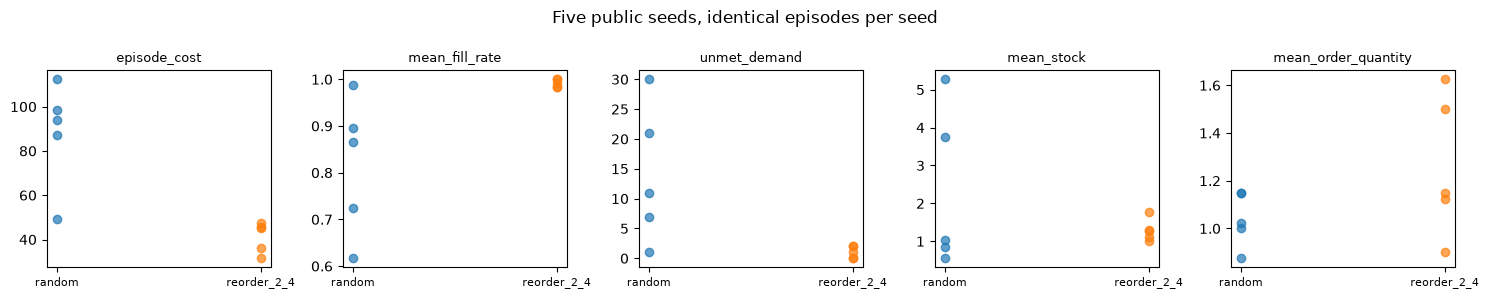

In [5]:
from shared.data import PUBLIC_SEEDS
def evaluate_student_policies(policies,seeds):
    rows=[]
    for seed in tuple(seeds):
        for name,policy in policies.items():
            env=InventoryControlEnv(); obs,_=env.reset(seed=int(seed)); rng=np.random.default_rng(int(seed)+900001)
            cost=0.; fills=[]; unmet=0; stocks=[]; orders=[]; done=False
            while not done:
                action=policy(obs,rng)
                if action is None or not env.action_space.contains(int(action)):
                    raise ValueError(f'{name} returned invalid action {action!r} for obs {obs}')
                obs,reward,terminated,truncated,info=env.step(int(action))
                assert np.isclose(reward,-info['cost'])
                cost+=info['cost']
                fills.append(info['fill_rate'])          # step-level served/demand, 1 when demand==0
                unmet+=info['unmet_demand']
                stocks.append(info['stock_level'])
                orders.append(info['order_quantity'])    # physical quantity, not index
                done=terminated or truncated
            env.close()
            assert len(fills)==env.config.horizon
            rows.append({'seed':int(seed),'policy':name,'episode_cost':cost,'mean_fill_rate':float(np.mean(fills)),
                         'unmet_demand':int(unmet),'mean_stock':float(np.mean(stocks)),'mean_order_quantity':float(np.mean(orders))})
    return pd.DataFrame(rows)
baseline_results=evaluate_student_policies({'random':random_policy_student,'reorder_2_4':reorder_policy_student},PUBLIC_SEEDS)
if len(baseline_results): assert len(baseline_results)==10 and baseline_results.groupby('policy').seed.nunique().eq(5).all()
# Cross-check against the shared reference evaluator (same seeds, same action RNG) -> must match exactly
from shared.rl import evaluate_policies, random_policy, reorder_policy
reference=evaluate_policies({'random':random_policy,'reorder_2_4':reorder_policy},seeds=PUBLIC_SEEDS)
pd.testing.assert_frame_equal(baseline_results.reset_index(drop=True),reference.reset_index(drop=True),check_dtype=False)
metrics=['episode_cost','mean_fill_rate','unmet_demand','mean_stock','mean_order_quantity']
summary=baseline_results.groupby('policy')[metrics].agg(['mean','std']).round(3)
display(baseline_results.round(3)); display(summary)
fig,axes=plt.subplots(1,len(metrics),figsize=(15,3))
for ax,m in zip(axes,metrics):
    for p,g in baseline_results.groupby('policy'): ax.scatter([p]*len(g),g[m],alpha=.7)
    ax.set_title(m,fontsize=9); ax.tick_params(axis='x',labelsize=8)
fig.suptitle('Five public seeds, identical episodes per seed'); plt.tight_layout(); plt.show()

## Required interpretation

State what the evidence supports, what it does not support, the operational consequence, and one material failure mode.

In [6]:
interpretation=(
 "Supported: on the five public seeds (11, 23, 37, 51, 71) with identical demand paths per seed, the regime-aware reorder heuristic (targets 2 low / 4 high) "
 "has lower 40-step cost on every seed (mean 41.2 +/- 6.9 vs 88.2 +/- 23.7 for random) while also serving better (mean step fill rate 0.992 vs 0.818; 1.0 vs 14.0 unmet units per episode), "
 "and it does so with less average stock (1.29 vs 2.29) at the price of slightly larger orders (1.26 vs 1.04 units/step). "
 "Not supported: any claim about optimality, about other cost weights or demand processes, or a general ranking - this is five episodes of provisional public-seed development evidence, not a TDo1/TDo2 release claim. "
 "Operational consequence: the reorder heuristic is the comparator that TD4 Q-learning must beat on cost without losing fill rate or unmet demand; beating the random policy alone would prove nothing. "
 "Failure mode: reward alone hides how cost is incurred - random on seed 37 reaches 0.988 fill rate but costs 87.0 because it hoards stock (mean 5.3), "
 "so a learned policy could trade stockouts for holding cost (or the reverse under different weights) with a similar reward, which is why all five metrics must be reported together."
)
print(interpretation or 'Interpretation pending.')

Supported: on the five public seeds (11, 23, 37, 51, 71) with identical demand paths per seed, the regime-aware reorder heuristic (targets 2 low / 4 high) has lower 40-step cost on every seed (mean 41.2 +/- 6.9 vs 88.2 +/- 23.7 for random) while also serving better (mean step fill rate 0.992 vs 0.818; 1.0 vs 14.0 unmet units per episode), and it does so with less average stock (1.29 vs 2.29) at the price of slightly larger orders (1.26 vs 1.04 units/step). Not supported: any claim about optimality, about other cost weights or demand processes, or a general ranking - this is five episodes of provisional public-seed development evidence, not a TDo1/TDo2 release claim. Operational consequence: the reorder heuristic is the comparator that TD4 Q-learning must beat on cost without losing fill rate or unmet demand; beating the random policy alone would prove nothing. Failure mode: reward alone hides how cost is incurred - random on seed 37 reaches 0.988 fill rate but costs 87.0 because it hoa

## Optional Extension — ungraded

Freeze valid Core first. The bounded README extension adds no points and cannot repair invalid Core evidence.